# Регрессор: сколько продадут, если продажа будет

Вторая ступень модели. CatBoost учится **только на неделях с продажами** (таргет - `log1p` от продаж за неделю) и прогнозирует количество на неделе T + h при условии, что продажа будет. Решение "будет ли продажа" - в `03_classifier.ipynb`; вместе их собирает `01_start.ipynb`.

Почему только недели с продажами: если продажи нет, любое ненулевое число в SMAPE даёт 200 %, так что количество важно только там, где продажа будет. Поэтому и метрики ниже - только по неделям с продажами.

Код - `src/regressor.py` (модель, метрики, отбор признаков, анализ ошибок), признаки - `src/features.py`. Все метрики сравниваются с простым количеством: "сколько пара обычно продаёт за неделю, когда продаёт" (среднее ненулевых недель за 8 недель).

In [1]:
import sys; sys.path.insert(0, "../src")   # код проекта - в src/

import numpy as np
import pandas as pd
from core import *

# правки в src/ подхватываются без перезапуска ядра (методы, объявленные в ноутбуке, после этого перезапусти);
# на Kaggle не включаем: там старый IPython, и это расширение на новом Python не грузится
if not ON_KAGGLE:
    %load_ext autoreload
    %autoreload 2

import classifier, regressor
from features import GROUPS, overview, select

## Признаки

Общий запас признаков считается в `src/features.py` - одним кодом для обучения и прогноза, всё только по данным до недели отсчёта, окна не длиннее 24 недель. У каждой модели свой набор - список `FEATURES` в `src/regressor.py`; стартовые наборы выбраны на глаз, проверять их - разделом "Какие группы признаков помогают" ниже.

Поменять набор: насовсем - `regressor.FEATURES = select("лаги", "частота", ..., extra=["mean4"])` или правка списка в `src/regressor.py`; на один эксперимент - `features=[...]` в вызове (пример в конце).

In [2]:
overview(("регрессор", regressor.FEATURES), ("классификатор", classifier.FEATURES))

,признаки,что значат,регрессор,классификатор
лаги,"lag1, lag2, lag3, lag4",продажи пары за 1-4 последние недели,все,все
уровень,"mean4, mean8, mean13, mean24, med8, max8","средние за 4/8/13/24 недели, медиана и максиму...",все,2 из 6
частота,"nz4, nz8, nz13, nz24, ewm_nz, days4, days8",доля недель с продажами (4-24 недели; сглаженн...,1 из 7,все
обычное количество,"typ8, typ24, qty_per_day8, max_day8","сколько продают, когда продают: за неделю (8/2...",все,нет
давность,"since_last, since_first, days_since_sale, hist...","недель с последней и первой продажи, дней с по...",нет,все
тренды,"trend, art_trend, wh_trend","4 недели к 24: у пары, у товара на всех склада...",все,все
товар на всех складах,"art_mean4, art_nz4",продажи того же товара по всем складам и доля ...,все,все
остатки,"stock, stock_min7, stock_mean28, stock_le0_28,...","остаток на начало дня T, минимум за 7 дней, ср...",2 из 6,все
цена и скидка,"price8, price_trend, discount8","средняя цена за штуку за 8 недель, она же к 24...",все,1 из 3
география,"cities8, divisions8",в скольких городах и департаментах покупают за...,все,нет


## Настройки

Локально: каждая 4-я неделя отсчёта, 300 деревьев, без комбинаций категорий; недель с продажами немного, поэтому обучение на фолде - секунды. На Kaggle (`make run NB=04`) настройки сами становятся полными и обучение идёт на GPU.

In [3]:
regressor.PARAMS, regressor.ORIGIN_STEP, regressor.ABLATION

({'iterations': 1500,
  'learning_rate': 0.05,
  'depth': 8,
  'loss_function': 'RMSE',
  'random_seed': 42,
  'verbose': 0,
  'allow_writing_files': False,
  'thread_count': -1,
  'task_type': 'GPU'},
 1,
 {'origin_step': 2, 'iterations': 500})

## Обучение и метрики на главном фолде

Все метрики - только по неделям, где продажа была.

| Метрика | Что значит |
|---|---|
| MAE, RMSE | средняя ошибка в штуках (RMSE сильнее штрафует большие промахи) |
| WAPE | сумма ошибок к сумме продаж, % |
| SMAPE | как в итоговой метрике, но только по неделям с продажами |
| RMSLE | ошибка в логарифмах - в относительных долях |
| прогноз / факт | меньше 1 - занижает объём, больше 1 - завышает |
| доля завышений | как часто прогноз больше факта |

In [4]:
m = regressor.evaluate("season2025")
m["summary"]

,MAE,RMSE,WAPE,SMAPE,RMSLE,прогноз / факт,доля завышений
CatBoost,1.7148,3.8315,38.1028,41.1179,0.3953,0.8475,0.5586
обычное количество,1.7712,3.9137,39.3554,41.4658,0.4302,0.8461,0.3866


## Где ошибается

По горизонту и по тому, сколько пара обычно продаёт: мелкие и ходовые пары ошибаются по-разному.

In [5]:
display(m["by_horizon"])
m["by_segment"]

,SMAPE,SMAPE (обычное количество),прогноз / факт,недель с продажами
"горизонт, недель",,,,
1,37.9261,38.9544,1.0002,3548.0
2,38.7437,39.4882,0.9509,3760.0
3,39.7445,40.7219,0.8196,3990.0
4,40.3534,40.8017,0.8689,3921.0
5,40.6679,41.8685,0.8789,3876.0
6,42.3260,42.3162,0.8538,3934.0
7,41.5271,41.0431,0.8434,3763.0
8,43.5030,43.5758,0.7660,3862.0
9,44.7312,43.9891,0.7025,4143.0


,недель с продажами,SMAPE,SMAPE (обычное количество),WAPE,WAPE (обычное количество),прогноз / факт
обычно 1 шт.,13450.0,33.9523,30.1809,39.7861,38.3258,0.8802
обычно 2-4 шт.,14227.0,47.2059,51.2812,48.2295,51.8111,0.8142
обычно больше 4 шт.,7120.0,42.4891,43.1705,33.2720,34.1134,0.8548


## Калибровка

Если регрессор говорит "3 штуки", сколько в среднем продают на самом деле. Точки ниже диагонали - занижает, выше - завышает.

,недель,средний прогноз,средний факт
"прогноз, шт.",,,
1-1.5,12334.0,1.2629,1.3873
1.5-2,6126.0,1.7226,1.9736
2-3,6320.0,2.4456,3.0960
3-5,4736.0,3.7937,4.8649
5-10,3074.0,6.7571,8.4893
10-inf,2207.0,23.7420,26.5976


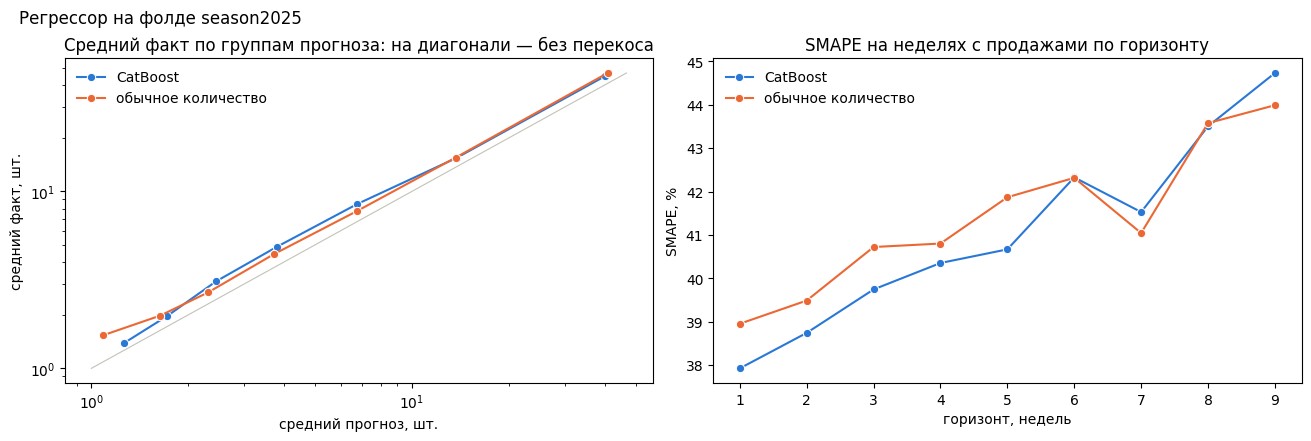

In [6]:
display(m["calibration"])
regressor.plot("season2025")

## Все фолды

In [7]:
regressor.summary()

MAE    RMSE     WAPE    SMAPE   RMSLE  \
season2025 CatBoost            1.7148  3.8315  38.1028  41.1179  0.3953   
           обычное количество  1.7712  3.9137  39.3554  41.4658  0.4302   
season2024 CatBoost            1.5556  3.2859  44.7209  42.5781  0.4072   
           обычное количество  1.5942  3.2553  45.8291  42.4243  0.4507   
recent     CatBoost            2.0463  4.5915  37.2284  41.3643  0.3946   
           обычное количество  2.0994  4.5547  38.1935  42.1362  0.4193   

                               прогноз / факт  доля завышений  
season2025 CatBoost                    0.8475          0.5586  
           обычное количество          0.8461          0.3866  
season2024 CatBoost                    0.8358          0.5660  
           обычное количество          0.8173          0.3468  
recent     CatBoost                    0.8749          0.5594  
           обычное количество          0.8688          0.4502

## Важность признаков

Сколько каждый признак дал модели. Низкая важность ещё не значит "не нужен" - это проверяет следующий раздел.

In [8]:
m["importance"].head(20)

mean8             12.0235
art_mean4          8.8591
warehouse_name     8.6884
mean4              7.7335
week_of_year       7.7071
category_lvl_2     6.1484
typ24              5.4576
art_trend          4.8114
price8             3.8800
category_lvl_1     3.5308
med8               2.6065
discount8          2.1245
stock              2.1141
month              2.0468
holidays           1.6790
lag1               1.6218
typ8               1.6216
mean13             1.5965
stock_mean28       1.5570
price_trend        1.4267
Name: важность, dtype: float64

## Какие группы признаков помогают

Каждая строка - отдельная модель на облегчённых настройках (`regressor.ABLATION`), только на главном фолде:
- группа **в наборе** - её убрали; группы **нет в наборе** - её добавили;
- польза = (метрика с группой) - (метрика без группы) в сторону "лучше": больше нуля - группа помогает, меньше - мешает;
- вывод - по SMAPE на неделях с продажами; разница меньше 0.1 п.п. считается шумом.

Локально - минут 1-2; на Kaggle настройки полнее и точнее. Прежде чем менять набор, проверь вывод на другом фолде: `regressor.feature_ablation("season2024")`.

In [9]:
ablation = regressor.feature_ablation("season2025")
ablation

,в наборе,что проверили,SMAPE,RMSLE,WAPE,польза для SMAPE,польза для RMSLE,польза для WAPE,вывод
набор FEATURES целиком,,,41.515329,0.395786,38.675331,NaN,NaN,NaN,
лаги,да,убрали,41.576376,0.396421,38.853357,0.061048,0.000634,0.178027,почти не влияет
уровень,да,убрали,41.650313,0.396681,38.877952,0.134984,0.000895,0.202621,помогает
частота,да,убрали,41.61175,0.395988,38.697601,0.096421,0.000202,0.02227,почти не влияет
обычное количество,да,убрали,41.616769,0.396074,38.920099,0.10144,0.000288,0.244768,помогает
давность,нет,добавили,41.526056,0.395855,38.680405,-0.010727,-0.000069,-0.005075,почти не влияет
тренды,да,убрали,41.731685,0.398598,39.003316,0.216357,0.002811,0.327985,помогает
товар на всех складах,да,убрали,42.02226,0.39851,39.095583,0.506931,0.002724,0.420252,помогает
остатки,да,убрали,41.711977,0.396649,38.88562,0.196648,0.000863,0.210289,помогает
цена и скидка,да,убрали,41.650175,0.395617,38.585475,0.134846,-0.000169,-0.089856,помогает


## Анализ ошибок

Где регрессор ошибается (только недели с продажами):
- `by_fact` - как прогноз следует за фактом: обычно маленькие недели завышены, а большие занижены (модель "тянет к среднему");
- по категориям и складам - ошибка, перекос (прогноз / факт) и доля всей ошибки в штуках;
- самые большие промахи - что видела модель, когда промахнулась. Часто это всплески: пара обычно продаёт пару штук, а на неделе - сотню.

In [10]:
err = regressor.error_analysis("season2025")
display(err["by_fact"])
display(err["by_category"])
err["by_warehouse"]

,недель,средний факт,средний прогноз,прогноз / факт,доля всей ошибки
факт за неделю,,,,,
1 шт.,14124,1.000,1.584,1.584,0.138
2-3 шт.,10086,2.349,2.228,0.948,0.143
4-9 шт.,7080,5.668,4.152,0.733,0.277
10+ шт.,3507,22.429,16.675,0.743,0.442


,недель с продажами,SMAPE,WAPE,прогноз / факт,доля всей ошибки
category_lvl_1,,,,,
category_lvl_1_5,12463,41.542,37.670,0.835,0.358
category_lvl_1_4,4593,39.682,45.199,0.780,0.117
category_lvl_1_0,2414,41.333,27.842,0.944,0.117
category_lvl_1_10,3104,42.970,40.896,0.869,0.084
category_lvl_1_9,2324,43.339,37.698,0.848,0.078
category_lvl_1_7,1697,46.751,52.152,0.611,0.061
category_lvl_1_1,2473,37.544,34.169,0.977,0.059
category_lvl_1_8,1427,40.377,42.439,0.719,0.050
category_lvl_1_3,1730,37.165,41.602,0.896,0.028


,недель с продажами,SMAPE,WAPE,прогноз / факт,доля всей ошибки
warehouse_name,,,,,
warehouse_name_2,6329,48.608,37.041,0.799,0.355
warehouse_name_3,6122,46.427,38.768,0.865,0.249
warehouse_name_4,3034,39.834,39.936,0.801,0.071
warehouse_name_5,3326,40.169,37.818,0.925,0.069
warehouse_name_10,3017,37.850,36.450,0.939,0.055
warehouse_name_6,2951,39.686,41.718,0.927,0.050
warehouse_name_7,2307,38.405,38.947,0.835,0.043
warehouse_name_1,2287,37.892,39.733,0.849,0.039
warehouse_name_8,2100,35.797,38.595,0.905,0.031


In [11]:
err["biggest_misses"]

,warehouse_name,article,category_lvl_1,h,факт,прогноз,ошибка,typ8,mean8,max8,nz8,trend,price_trend,stock
22361,warehouse_name_2,char_article_177,category_lvl_1_4,6,201.0,2.164,-198.836,2.333,1.750,4.0,0.75,0.390,1.102,31.0
31974,warehouse_name_3,char_article_419,category_lvl_1_8,7,133.0,40.389,-92.611,41.375,41.375,50.0,1.00,1.301,0.995,90.0
21694,warehouse_name_2,char_article_11,category_lvl_1_7,5,128.0,37.801,-90.199,28.500,28.500,39.0,1.00,1.394,1.037,137.0
24713,warehouse_name_2,char_article_411,category_lvl_1_5,9,197.0,111.456,-85.544,126.625,126.625,156.0,1.00,1.072,0.978,188.0
24783,warehouse_name_2,char_article_419,category_lvl_1_8,7,127.0,51.104,-75.896,56.750,56.750,69.0,1.00,1.318,0.994,151.0
24781,warehouse_name_2,char_article_419,category_lvl_1_8,5,129.0,58.818,-70.182,56.750,56.750,69.0,1.00,1.318,0.994,151.0
31904,warehouse_name_3,char_article_411,category_lvl_1_5,9,127.0,60.447,-66.553,74.625,74.625,89.0,1.00,1.054,0.974,99.0
24506,warehouse_name_2,char_article_391,category_lvl_1_0,9,228.0,166.014,-61.986,183.125,183.125,200.0,1.00,1.005,0.949,590.0
30052,warehouse_name_3,char_article_227,category_lvl_1_4,2,69.0,7.481,-61.519,11.625,11.625,28.0,1.00,1.109,1.025,0.0
38888,warehouse_name_4,char_article_391,category_lvl_1_0,9,85.0,31.572,-53.428,42.875,42.875,56.0,1.00,1.051,0.977,151.0


## Вклад в итоговый скор

Метод `regressor`: "будет продажа" решает простое правило (продажи хотя бы в половине из 8 недель), количество - регрессор. Для честного сравнения - то же правило с "обычным количеством" (`amount="simple"`).

In [12]:
backtest("regressor", note="только регрессор")
backtest("regressor", amount="simple", note="простое правило + обычное количество")
j = journal()
j[j.note.isin(["только регрессор", "простое правило + обычное количество"])]

,method,params,note,score_season2025,score_season2024,score_recent,smape,wape,rmse,bias,rmsle,pred/true
run,,,,,,,,,,,,
1,regressor,{},только регрессор,0.865,0.901,0.853,62.208,53.554,2.680,95.324,0.529,0.826
2,regressor,{'amount': 'simple'},простое правило + обычное количество,0.876,0.908,0.858,62.530,54.645,2.722,97.207,0.537,0.828


## Эксперимент: свой набор признаков

Пример - регрессор с группой "давность", которой нет в стартовом наборе (обучится новая модель). Понравится - `regressor.FEATURES = variant`.

In [13]:
variant = regressor.FEATURES + [c for c in GROUPS["давность"][0] if c not in regressor.FEATURES]
m2 = regressor.evaluate("season2025", features=variant)
pd.concat({"FEATURES": m["summary"].iloc[0], "+ давность": m2["summary"].iloc[0]}, axis=1)

,FEATURES,+ давность
MAE,1.7148,1.7234
RMSE,3.8315,3.8659
WAPE,38.1028,38.2925
SMAPE,41.1179,41.2387
RMSLE,0.3953,0.3960
прогноз / факт,0.8475,0.8451
доля завышений,0.5586,0.5582
